<a href="https://colab.research.google.com/github/furalmiqbadi/PCVK26_01_AbdulGhofurAlmiqbadi/blob/main/Week6_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# D. PRAKTIKUM FILTER

In [5]:
NAMA = 'Abdul Ghofur Almiqbadi'
NIM  = '244107020155'
print(NAMA, NIM)

Abdul Ghofur Almiqbadi 244107020155


In [6]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

In [8]:
def convolution2d(image, kernel, stride, padding):
  img_h, img_w = image.shape
  ker_h, ker_w = kernel.shape

  # hitung ukuran output
  out_h = (img_h - ker_h) // stride + 1
  out_w = (img_w - ker_w) // stride + 1
  output = np.zeros((out_h, out_w), dtype=np.float64)

  # proses konvolusi
  for y in range(out_h):
    for x in range(out_w):
      roi = image[y*stride : y*stride + ker_h,
        x*stride : x*stride + ker_w]
      output[y, x] = np.sum(roi * kernel)

  # clip nilai ke rentang 0-255
  output = np.clip(output, 0, 255).astype(np.uint8)
  return output

array([[179,   0,  70, ..., 118, 167, 249],
       [210,   0,   0, ...,  35, 111,  35],
       [255, 113,   0, ..., 233,  20,  64],
       ...,
       [148, 209, 100, ...,  45, 143,  81],
       [168, 131, 206, ..., 120,  56, 114],
       [255, 241, 201, ..., 150, 143, 159]], dtype=uint8)
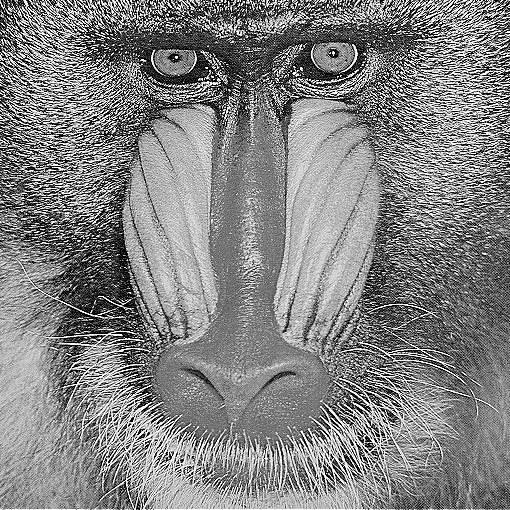

In [9]:
base = '/content/drive/MyDrive/3-Tugas/PCVK/'
img = cv.imread(base + 'mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# image sharpen
kernel_sharpen = np.array([[ 0, -1,  0],
                           [-1,  5, -1],
                           [ 0, -1,  0]])

convolution2d(img_gray, kernel_sharpen, 1, 2)

In [10]:
# kernel average filter
kernel_average = np.array([[1, 1, 1],
                           [1, 1, 1],
                           [1, 1, 1]]) / 9

# kernel low pass filter
kernel_lowpass = np.array([[1, 1, 1],
                           [1, 4, 1],
                           [1, 1, 1]]) / 12

# kernel high pass filter
kernel_highpass = np.array([[-1,  0,  1],
                            [-1,  0,  3],
                            [-3,  0,  1]])

# kernel sharpen
kernel_sharpen = np.array([[ 0, -1,  0],
                           [-1,  5, -1],
                           [ 0, -1,  0]])

# kernel emboss
kernel_emboss = np.array([[-2, -1,  0],
                          [-1,  1,  1],
                          [ 0,  1,  2]])

# kernel left sobel edge detection
kernel_sobel_left = np.array([[ 1,  0, -1],
                              [ 2,  0, -2],
                              [ 1,  0, -1]])

# kernel canny edge detection
kernel_canny = np.array([[-1, -1, -1],
                         [-1,  8, -1],
                         [-1, -1, -1]])

# kernel gaussian 21x21
kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_kernel = cv.getGaussianKernel(kernel_size, sigma)
gauss_kernel = gaussian_kernel @ gaussian_kernel.transpose()

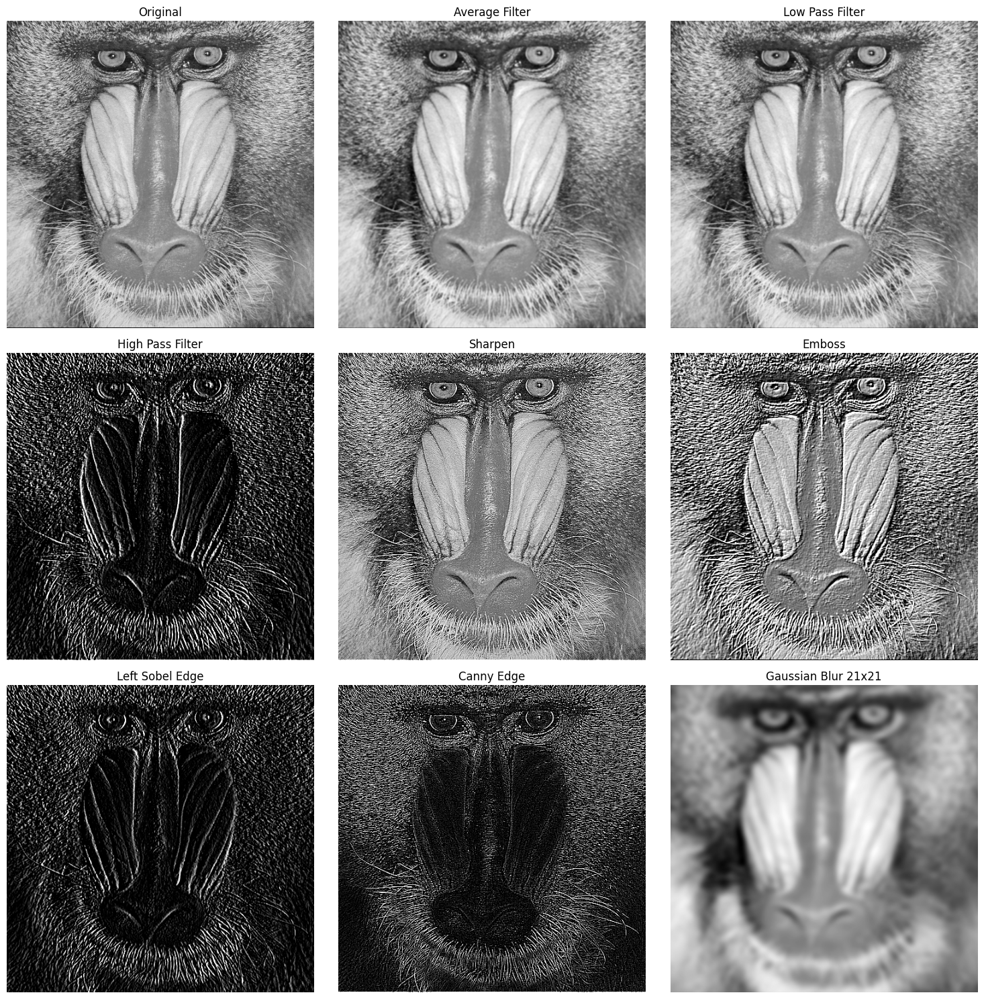

In [11]:
results = {}
results['Average Filter'] = convolution2d(img_gray, kernel_average, stride=1, padding=1)
results['Low Pass Filter'] = convolution2d(img_gray, kernel_lowpass, stride=1, padding=1)
results['High Pass Filter'] = convolution2d(img_gray, kernel_highpass, stride=1, padding=1)
results['Sharpen'] = convolution2d(img_gray, kernel_sharpen,    stride=1, padding=1)
results['Emboss'] = convolution2d(img_gray, kernel_emboss,     stride=1, padding=1)
results['Left Sobel Edge'] = convolution2d(img_gray, kernel_sobel_left, stride=1, padding=1)
results['Canny Edge'] = convolution2d(img_gray, kernel_canny,      stride=1, padding=1)
results['Gaussian Blur 21x21'] = convolution2d(img_gray, gauss_kernel,stride=1, padding=10)

# output
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

axes[0].imshow(img_gray, cmap='gray')
axes[0].set_title('Original')
axes[0].axis('off')

for i, (name, res) in enumerate(results.items(), start=1):
  axes[i].imshow(res, cmap='gray')
  axes[i].set_title(name)
  axes[i].axis('off')

plt.tight_layout()
plt.show()

# E. FILTER LIBRARY DAN FILTER MODERN

## Percobaan 1:

In [12]:
def show_side_by_side(images, titles, figsize=(15, 5)):
  plt.figure(figsize=figsize)
  for i, (img, title) in enumerate(zip(images, titles)):
    if len(img.shape) == 2:  # grayscale
      plt.subplot(1, len(images), i+1)
      plt.imshow(img, cmap="gray")
    else:  # color
      plt.subplot(1, len(images), i+1)
      plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
  plt.show()

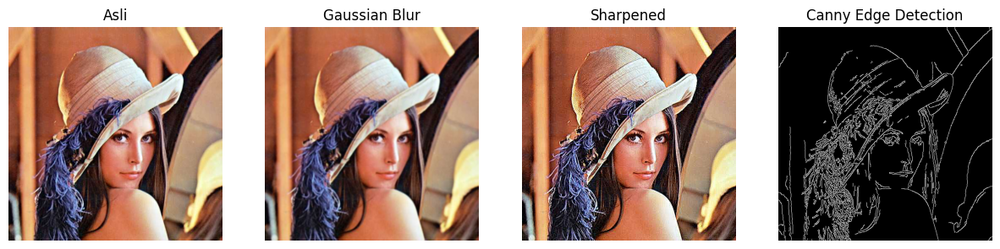

In [13]:
img = cv.imread(base + 'lena.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img, (7, 7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)

show_side_by_side([img, blur, sharpened, edges],
                  ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"])

## Percobaan 2:

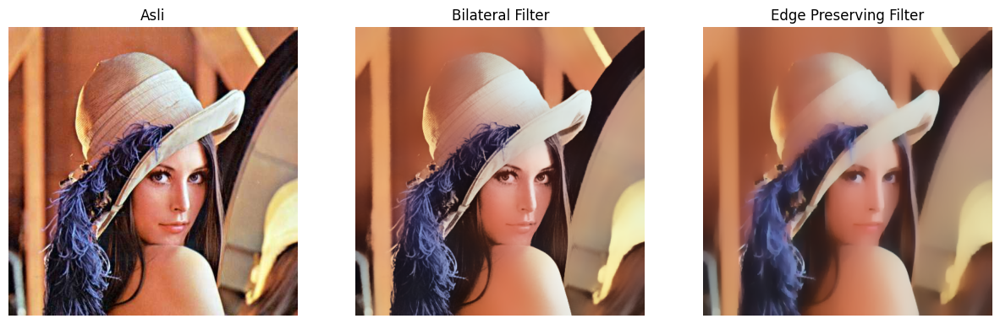

In [14]:
# bilateral filter (edge-preserving)
bilateral = cv.bilateralFilter(img, 50, 100, 100)

# edge preserving filter (alternatif Guided Filter)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side([img, bilateral, edge_preserve],
                  ["Asli", "Bilateral Filter", "Edge Preserving Filter"])

## Percobaan 3:

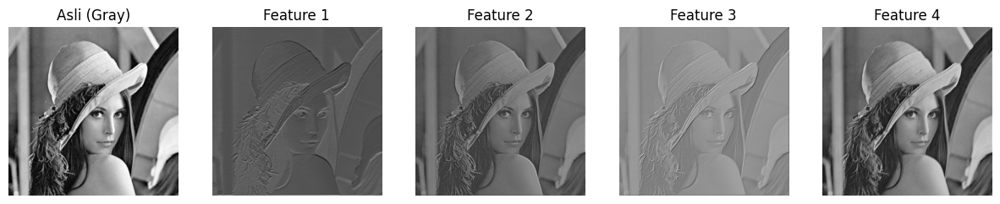

In [15]:
import torch
import torch.nn as nn

# definisikan model CNN
class SimpleCNN(nn.Module):
  def __init__(self):
    super(SimpleCNN, self).__init__()
    self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

  def forward(self, x):
    return self.conv1(x)

model = SimpleCNN()

# ubah gambar ke tensor
img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

# CNN
with torch.no_grad():
    features = model(img_tensor)

# visualisasi feature maps
feature_maps = [features[0, i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray] + feature_maps, ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))])

## Percobaan 4:

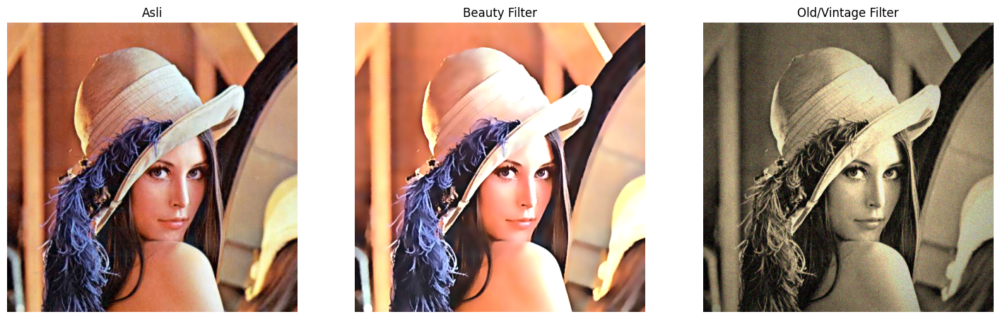

In [16]:
# beauty filter
# 1. smoothing kulit dengan bilateral filter
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

# 2. unsharp masking (pertajam mata/bibir)
gaussian = cv.GaussianBlur(smooth, (0, 0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

# 3. brightness & contrast
alpha = 1.2   # contrast
beta = 15     # brightness
beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)


# old/vintage filter

# 1. sepia tone
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

# 2. vignette
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols * 0.6)
kernel_y = cv.getGaussianKernel(rows, rows * 0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
  vignette[:, :, i] = vignette[:, :, i] * mask

# 3. noise/grain
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)


# output
show_side_by_side([img, beauty, old_img],
                  ["Asli", "Beauty Filter", "Old/Vintage Filter"],
                  figsize=(18, 6))

## Percobaan 5:

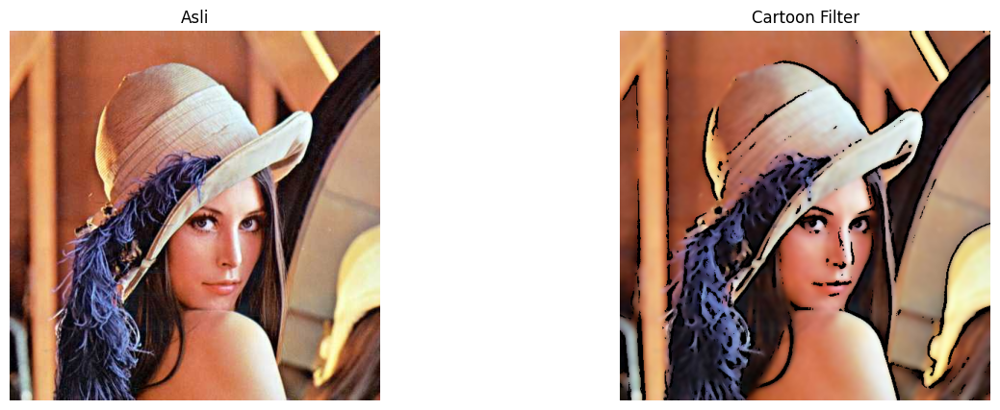

In [17]:
# filter anime / cartoon
# 1. edge detection (pakai median blur dulu agar gambar menjadi lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(gray_blur, 255,
                             cv.ADAPTIVE_THRESH_MEAN_C,
                             cv.THRESH_BINARY, 9, 9)

# 2. bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

# 3. gabungkan (cartoonize)
cartoon = cv.bitwise_and(color, color, mask=edges)

# output
show_side_by_side([img, cartoon], ["Asli", "Cartoon Filter"])

## Percobaan 6:

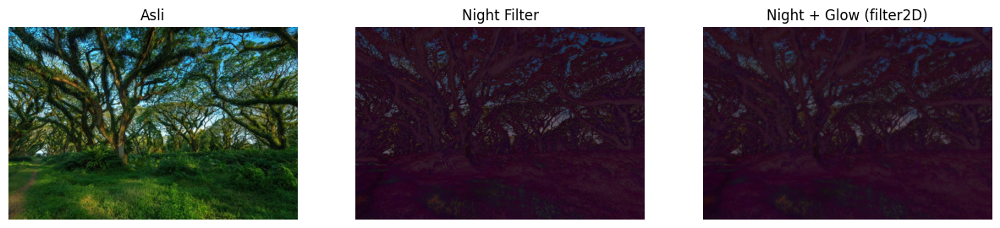

In [18]:
img = cv.imread(base + 'djawatan.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# night gfilter
# 1. gelapkan (contrast turun, brightness negatif)
night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

# 2. tambah bias biru
blue_tint = np.full_like(night, (50, 0, 100))  # BGR
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

# 3. efek glow di area terang dengan filter2D (blur kernel)
kernel = np.ones((15, 15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)

# kombinasikan asli + glow
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

# output
show_side_by_side([img, night, night_glow],
                  ["Asli", "Night Filter", "Night + Glow (filter2D)"])

## Percobaan 7

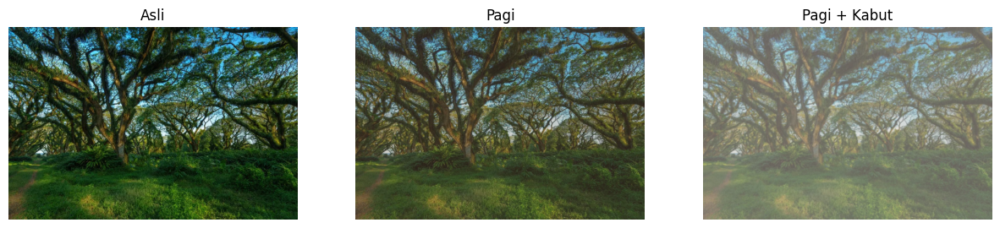

In [19]:
# filter suasana pagi dan kabut
# 1. kurangi kontras & cerahkan
alpha = 0.9   # contrast
beta = 20     # brightness
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

# 2. tambahkan warm tone (kemerahan / oranye)
warm_tint = np.full_like(soft, (40, 70, 120))  # BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# 3. tambahkan haze (kabut tipis) dengan filter2D
kernel = cv.getGaussianKernel(3, 3) # kernel blur Gaussian-like (efek kabut)
kernel = kernel @ kernel.T  # jadikan 2D kernel
kabut = cv.filter2D(pagi, -1, kernel)

# tambah layer putih untuk kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

# output
show_side_by_side([img, pagi, kabut],
                  ["Asli", "Pagi", "Pagi + Kabut"])

# Tugas Praktikum

## 1. Tugas Analisis: Perbandingan Mean Filter (Blur Biasa) vs. Median Filter pada Noise “Salt and Pepper”
* Tambahkan noise bintik hitam-putih (Salt and Pepper) ke sebuah citra keabuan (grayscale).
* Terapkan Mean Filter(3 x 3) dan Median Filter (3 x 3).
* Amati dan analisis secara visual mengapa Median Filter jauh lebih bersih dalam menghapus noise tersebut dibanding Mean Filter.

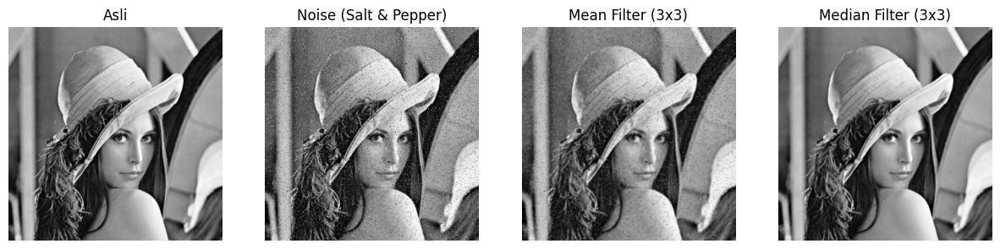

In [25]:
img_bgr = cv.imread(base + 'lena.jpg')
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# fungsi noise Salt and Pepper
def add_salt_and_pepper(image, prob):
  noisy = np.copy(image)
  total_pixels = image.size
  num_salt = int(prob * total_pixels * 0.5)
  num_pepper = int(prob * total_pixels * 0.5)

  # salt (bintik putih)
  coords = [np.random.randint(0, i - 1, num_salt) for i in image.shape]
  noisy[coords[0], coords[1]] = 255

  # pepper (bintik hitam)
  coords = [np.random.randint(0, i - 1, num_pepper) for i in image.shape]
  noisy[coords[0], coords[1]] = 0

  return noisy

noisy_img = add_salt_and_pepper(img_gray, 0.05)

# mean filter (3x3)
mean_filtered = cv.blur(noisy_img, (3, 3))

# median filter (3x3)
median_filtered = cv.medianBlur(noisy_img, 3)


# output
show_side_by_side([img_gray, noisy_img, mean_filtered, median_filtered],
                  ["Asli", "Noise (Salt & Pepper)", "Mean Filter (3x3)", "Median Filter (3x3)"])

Berdasarkan analisis visual pada gambar, Median Filter terlihat lebih efektif dalam menghapus noise Salt & Pepper dibandingkan Mean Filter. Hal ini disebabkan oleh cara kerja masing-masing filter. Pada Mean Filter bekerja dengan menghitung rata-rata nilai piksel di dalam kernel, sehingga nilai outlier dari noise Salt & Pepper tetap mempengaruhi hasil rata-rata yang menyebabkan noise tidak sepenuhnya hilang dan citra menjadi buram. Sebaliknya, Median Filter bekerja dengan mengambil nilai median atau nilai tengah dari sekumpulan piksel dalam kernel dan Nilai outlier dari noise Salt & Pepper yang jumlahnya sedikit dibandingkan piksel normal di sekitarnya, sehingga nilai median akan secara otomatis mengabaikan nilai tersebut yang membuat noise berhasil dihapus dengan baik sementara detail tepi citra tetap terjaga dan tidak mengalami efek blur seperti pada Mean Filter.


## 2. Tugas Evaluasi: Pemilihan Ukuran Kernel terbaik untuk Menajamkan Citra (Sharpening)
* Buat kernel penajaman (Sharpening Kernel) ukuran 3 x 3 dan 5 x 5.
* Terapkan pada citra yang sedikit buram (blurry).
* Evaluasi hasilnya berdasarkan aspek Kejelasan Tepi vs. Kadar Noise/Noise Distortion yang dihasilkan. Tentukan kernel mana yang paling optimal untuk digunakan sehari-hari.

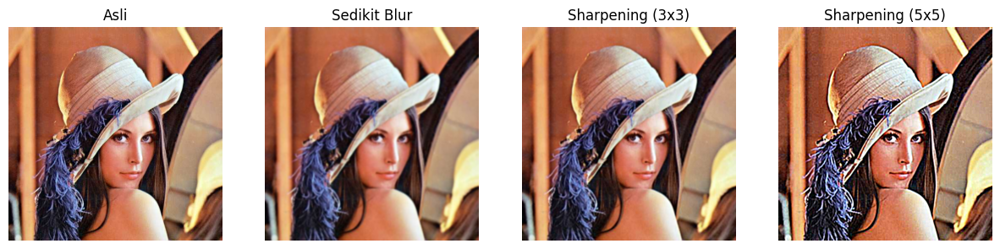

In [36]:
# uat citra sedikit buram
blurry_img = cv.GaussianBlur(img_bgr, (7, 7), 0)

# kernel penajaman 3x3 dan 5x5
kernel_3x3 = np.array([[0, -1, 0],
                       [-1, 5, -1],
                       [0, -1, 0]])

kernel_5x5 = np.array([[ 0,  0, -1,  0,  0],
                       [ 0, -1, -2, -1,  0],
                       [-1, -2, 17, -2, -1],
                       [ 0, -1, -2, -1,  0],
                       [ 0,  0, -1,  0,  0]])

# terapkan kernel
sharp_3x3 = cv.filter2D(blurry_img, -1, kernel_3x3)
sharp_5x5 = cv.filter2D(blurry_img, -1, kernel_5x5)

# output
show_side_by_side([img_bgr, blurry_img, sharp_3x3, sharp_5x5],
                  ["Asli", "Sedikit Blur", "Sharpening (3x3)", "Sharpening (5x5)"])

Berdasarkan analisis visual pada gambar, kernel 3×3 adalah pilihan paling optimal untuk penggunaan sehari-hari karena menjaga keseimbangan yang terbaik antara ketajaman dan noise tanpa merusak detail asli atau membuat terlalu tajam, selain itu secara komputasi hasilnya tetap terlihat natural. Sebaliknya, kernel 5×5 sebaiknya hanya digunakan untuk kasus khusus seperti gambar yang sangat blur, karena cenderung menghasilkan ketajaman yang berlebihan dan tampilan yang tidak natural.



## 3. Tugas Kreasi: Filter Kartun Sederhana
* Buatlah sebuah fungsi kustom bernama kartun(image) yang menggabungkan:
* * Penghalusan warna menggunakan **Bilateral Filter** agar area warna menjadi rata.
* * Deteksi garis tepi menggunakan **Adaptive Thresholding** atau **Canny Edge**.
* * Penggabungan (kombinasi) keduanya menggunakan operasi logika/perkalian piksel.
* Tampilkan hasil citra asli dengan citra efek kartun bersebelahan.

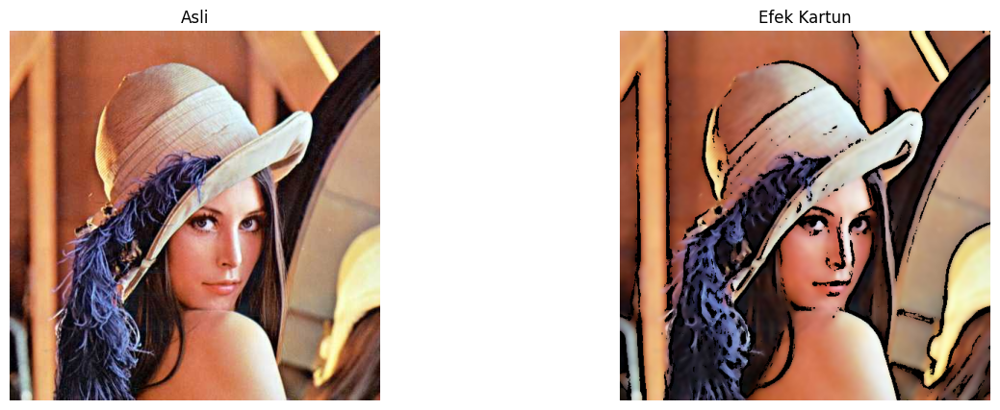

In [50]:
# fungsi kustom kartun
def kartun(image):
    # menghaluskan warna tetapi mempertahankan tepi dengan Bilateral Filter
    color_smoothed = cv.bilateralFilter(image, d=9, sigmaColor=150, sigmaSpace=150)

    # deteksi garis tepi menggunakan Adaptive Thresholding
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    gray_blur = cv.medianBlur(gray, 9)  # blur agar noise berkurang dan garis lebih bersih
    edges = cv.adaptiveThreshold(gray_blur, 255,
                                 cv.ADAPTIVE_THRESH_MEAN_C,
                                 cv.THRESH_BINARY,
                                 blockSize=9, C=5)

    # gabungkan warna halus dengan outline hitam
    cartoon_img = cv.bitwise_and(color_smoothed, color_smoothed, mask=edges)

    return cartoon_img

# panggil fungsi
img_cartoon = kartun(img_bgr)

# output
show_side_by_side([img_bgr, img_cartoon],
                  ["Asli", "Efek Kartun"])